# به نام خدا

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer

In [56]:
X, y = load_breast_cancer(as_frame=True, return_X_y=True) # برای اینکه فقط دیتا و تارگت برگرده ونه بیشتر

In [57]:
df_full = pd.concat([X, y], axis=1)

In [58]:
df_full

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


<div dir='rtl'>

هدف پیداکردن سرطان خوش خیم یا بدخیم هست.

In [59]:
df_full.shape

(569, 31)

In [60]:
df_full.target.value_counts()

target
1    357
0    212
Name: count, dtype: int64

<div dir='rtl'>

212 تا بدخیم(0) و 357 تا خوش خیم(1)

In [61]:
# drop primeter and area features
df_full.drop(columns=['mean perimeter', 'mean area', 'worst perimeter', 'worst area', "area error", "perimeter error"], inplace=True)

In [62]:
df_full

,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,...,fractal dimension error,worst radius,worst texture,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,...,0.006193,25.380,17.33,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,...,0.003532,24.990,23.41,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,...,0.004571,23.570,25.53,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,...,0.009208,14.910,26.50,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,...,0.005115,22.540,16.67,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,...,0.004239,25.450,26.40,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,...,0.002498,23.690,38.25,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,...,0.003892,18.980,34.12,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,...,0.006185,25.740,39.42,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [64]:
df_full.shape # پنج ستون حذف شد

(569, 25)

In [65]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean smoothness          569 non-null    float64
 3   mean compactness         569 non-null    float64
 4   mean concavity           569 non-null    float64
 5   mean concave points      569 non-null    float64
 6   mean symmetry            569 non-null    float64
 7   mean fractal dimension   569 non-null    float64
 8   radius error             569 non-null    float64
 9   texture error            569 non-null    float64
 10  smoothness error         569 non-null    float64
 11  compactness error        569 non-null    float64
 12  concavity error          569 non-null    float64
 13  concave points error     569 non-null    float64
 14  symmetry error           5

In [ ]:
df = df_full.filter(regex='mean|target')

<div dir='rtl'>

دیتا رو به سه دسته بندی تقسیمش کردیم. فعلا mean ولی در آینده با error و worst دوباره نوشته خواهد شد.

In [67]:
df

,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,target
0,17.99,10.38,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,0
1,20.57,17.77,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0
2,19.69,21.25,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0
3,11.42,20.38,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0
4,20.29,14.34,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0
...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,0
565,20.13,28.25,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0
566,16.60,28.08,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0
567,20.60,29.33,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0


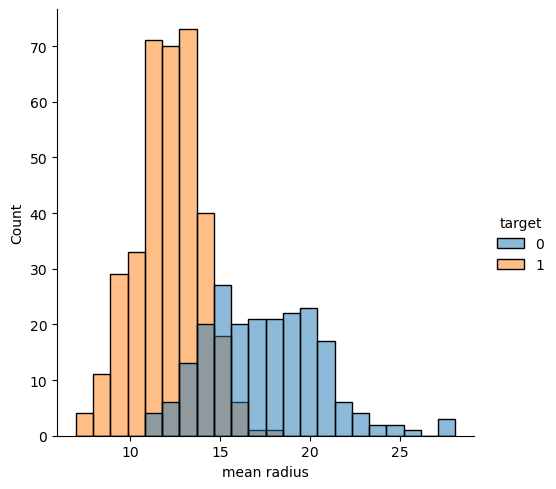

In [68]:
sns.displot(
    data=df,
    x="mean radius",
    hue='target'
)

<div dir='rtl'>

سلول های بدخیم میانگین شعاع بزرگتری نسبت به خوش خیم دارند.

<Axes: >

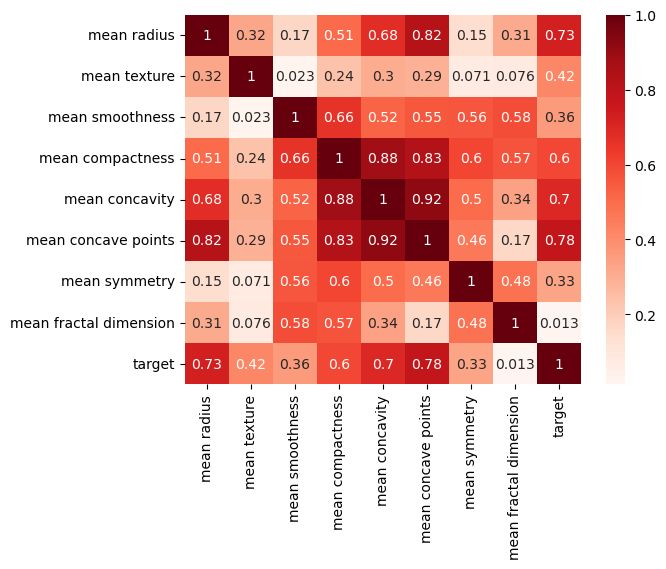

In [69]:
sns.heatmap(
    abs(df.corr()),
    annot=True,
    cmap="Reds"
)

<div dir='rtl'>

mean perimeter و mean area ارتباط خیلی زیادی با خود mean radius دارند و عملا انگار تکرار شده اند. حتی در دسته های error و worst. پس بهتره حذفشون کنیم.